# Task 02


In [35]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

df = pd.read_csv("../data/train.csv",
                 parse_dates=["pickup_datetime", "dropoff_datetime"])

# print("Raw shape:", df.shape)
# print(df.dtypes)
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982,40.768,-73.965,40.766,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980,40.739,-73.999,40.731,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979,40.764,-74.005,40.710,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010,40.720,-74.012,40.707,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973,40.793,-73.973,40.783,N,435


In [36]:

#Data cleaning
def haversine_np(lon1, lat1, lon2, lat2):
    """Great-circle distance in km between two points (decimal degrees)."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

#Pre-cleaning diagnostics
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600)

print(df[["trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.01, .5, .99]))
print("\nNegative/zero durations:", (df.trip_duration <= 0).sum())
print("Durations > 6 h     :", (df.trip_duration > 6 * 3600).sum())
print("Zero-distance trips :", (df.distance_km == 0).sum())
print("Speed > 100 km/h    :", (df.speed_kmh > 100).sum())
print("Speed < 1 km/h      :", (df.speed_kmh < 1).sum())
print("Pickup outside NYC  :",
      ((~df.pickup_longitude.between(-74.3, -73.7)) |
       (~df.pickup_latitude.between(40.5, 41.0))).sum())
print("\npassenger_count distribution:\n", df.passenger_count.value_counts().sort_index())

#Show the effect of each filter
def summarize(name, mask):
    kept = mask.sum()
    print(f"{name:<38} kept {kept:>10,}  ({kept/len(df)*100:5.2f}%)")
    return mask

# 1. sensible duration: between 30 s and 6 h
m_dur  = df.trip_duration.between(30, 6 * 3600)
# 2. plausible average speed: between 1 and 100 km/h
m_spd  = df.speed_kmh.between(1, 100)
# 3. pickup and dropoff inside the NYC bounding box
m_box  = (df.pickup_longitude.between(-74.3, -73.7) &
          df.pickup_latitude .between(40.5, 41.0) &
          df.dropoff_longitude.between(-74.3, -73.7) &
          df.dropoff_latitude .between(40.5, 41.0))
# 4. non-zero distance (removes cancelled / GPS-stuck trips)
m_dist = df.distance_km > 0
# 5. valid passenger count
m_pass = df.passenger_count.between(1, 6)

print("\n--- Filter retention ---")
summarize("Duration 30 s – 6 h", m_dur)
summarize("Speed 1 – 100 km/h", m_spd)
summarize("Coordinates in NYC bbox", m_box)
summarize("Distance > 0", m_dist)
summarize("Passenger count 1–6", m_pass)

mask = m_dur & m_spd & m_box & m_dist & m_pass
df_clean = df.loc[mask].copy()

print("\nRows before cleaning:", f"{len(df):,}")
print("Rows after  cleaning:", f"{len(df_clean):,}",
      f"({len(df_clean)/len(df)*100:.2f}% retained)")

print("\nCleaned summary:")
print(df_clean[["trip_duration", "distance_km", "speed_kmh"]].describe())

       trip_duration   distance_km     speed_kmh
count  1,458,644.000 1,458,644.000 1,458,644.000
mean         959.492         3.439        14.414
std        5,237.432         4.294        14.968
min            1.000         0.000         0.000
1%            87.000         0.139         1.393
50%          662.000         2.092        12.784
99%        3,440.000        20.774        40.720
max    3,526,282.000     1,240.130     9,269.014

Negative/zero durations: 0
Durations > 6 h     : 2061
Zero-distance trips : 5897
Speed > 100 km/h    : 175
Speed < 1 km/h      : 13241
Pickup outside NYC  : 256

passenger_count distribution:
 passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64

--- Filter retention ---
Duration 30 s – 6 h                    kept  1,451,801  (99.53%)
Speed 1 – 100 km/h                     kept  1,445,228  (99.08%)
Coordinates in NYC bbox              

In [37]:

df_clean["pickup_date"]   = df_clean.pickup_datetime.dt.date
df_clean["pickup_hour"]   = df_clean.pickup_datetime.dt.hour
df_clean["pickup_dow"]    = df_clean.pickup_datetime.dt.dayofweek          # Mon=0 … Sun=6
df_clean["day_name"]      = df_clean.pickup_datetime.dt.day_name()
df_clean["is_weekend"]    = df_clean.pickup_dow >= 5
# (distance_km and speed_kmh were created before cleaning in Cell 1)

# sanity check
print(df_clean[["pickup_datetime","distance_km","trip_duration",
                "speed_kmh","pickup_dow","day_name","pickup_hour"]].head())

print("\nDay-of-week counts:")
print(df_clean.day_name.value_counts().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]))

      pickup_datetime  distance_km  trip_duration  speed_kmh  pickup_dow  \
0 2016-03-14 17:24:55        1.498            455     11.849           0   
1 2016-06-12 00:43:35        1.804            663      9.798           6   
2 2016-01-19 11:35:24        6.381           2124     10.815           1   
3 2016-04-06 19:32:31        1.485            429     12.458           2   
4 2016-03-26 13:30:55        1.188            435      9.830           5   

    day_name  pickup_hour  
0     Monday           17  
1     Sunday            0  
2    Tuesday           11  
3  Wednesday           19  
4   Saturday           13  

Day-of-week counts:
day_name
Monday       185308
Tuesday      200459
Wednesday    207871
Thursday     216049
Friday       220968
Saturday     218393
Sunday       192983
Name: count, dtype: int64


# 4 Location clusters [12 marks]
## 4.1 Heatmaps
Produce a heatmap of all of the trip pickups over (do not do a scatter plot...there are 1.5 million data points and this will almost certainly crash your computer):

    1. weekdays and weekends,
    2. morning and evening (choose reasonable hours).
    
Comment on any findings you make. [4 marks]

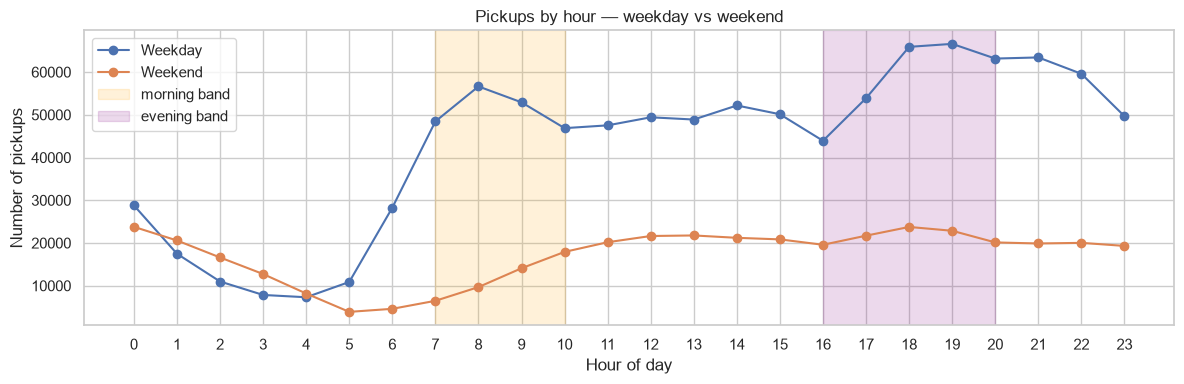

In [38]:
# Hourly counts, split by day type.
hourly = (
    df_clean.groupby(["is_weekend", "pickup_hour"])
    .size()
    .unstack(0)
    .rename(columns={False: "Weekday", True: "Weekend"})
)

fig, ax = plt.subplots(figsize=(12, 4))
hourly.plot(ax=ax, marker="o")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Number of pickups")
ax.set_title("Pickups by hour — weekday vs weekend")
ax.axvspan( 7, 10, color="orange", alpha=.15, label="morning band")
ax.axvspan(16, 20, color="purple", alpha=.15, label="evening band")
ax.legend()
plt.tight_layout()
plt.savefig("pickups_in_a_day.png")

## Justification of morning / evening bands

Morning = 07:00–09:59. The weekday hourly curve shows its sharpest pre-noon maximum here (~08:00). The window captures the entire commute ramp including its shoulders; a wider band (06:00–10:59) would drag in non-peak hours, and a narrower band (08:00–08:59) would discard the shoulders.

Evening = 17:00–19:59. The weekday evening curve has a broad, flatter maximum here (17:00–19:00). The window covers the whole after-work plateau, not just its tip.

The bands are deliberately identical for weekday and weekend. The comparison is only meaningful if we hold time-of-day fixed and let the day-type vary — this isolates the weekday-vs-weekend effect.

## Version 1

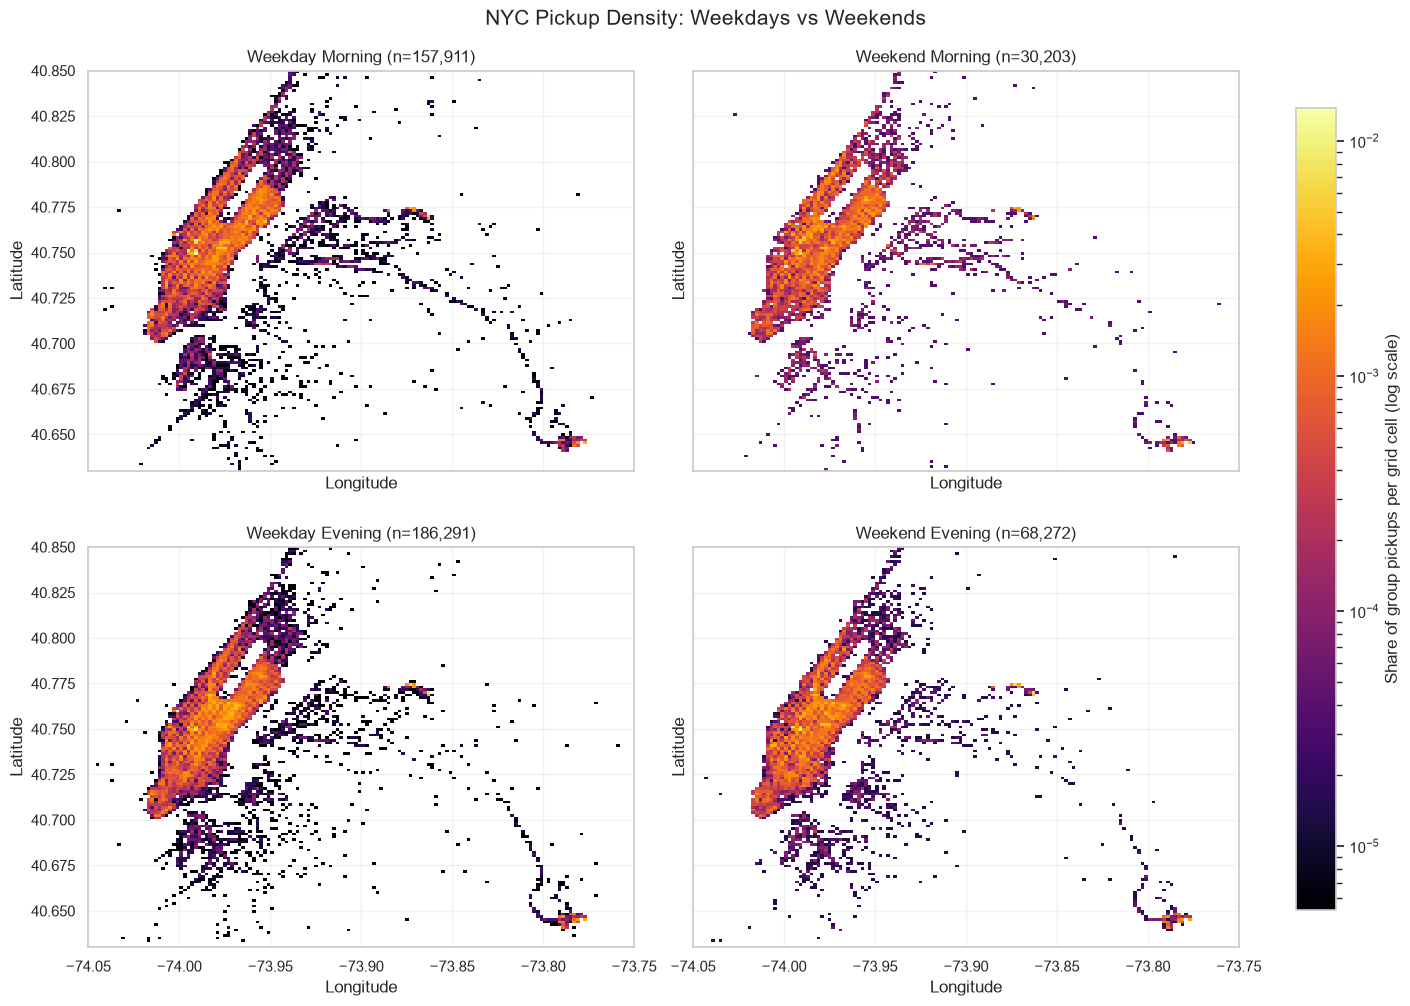

In [39]:
from matplotlib.colors import LogNorm

# 1. Prepare pick-up data

df_plot = df_clean.copy()

# pickup time is in datetime format
df_plot["pickup_datetime"] = pd.to_datetime(
    df_plot["pickup_datetime"], errors="coerce"
)

# Extract pickup hour and identify morning/evening
df_plot["pickup_hour"] = df_plot["pickup_datetime"].dt.hour

df_plot["day_type"] = np.where(
    df_plot["pickup_datetime"].dt.day_of_week >= 5,
    "Weekend",
    "Weekday"
)

df_plot["time_period"] = np.select(
    [
        df_plot["pickup_hour"].between(7, 9),
        df_plot["pickup_hour"].between(17, 19)
    ],
    ["Morning", "Evening"],
    default="other"
)

# Keep only the groups we want to compare
df_plot = df_plot[
    df_plot["time_period"].isin(["Morning", "Evening"])
].copy()

# 2. Define NYC map area
lon_min, lon_max = -74.05, -73.75
lat_min, lat_max = 40.63, 40.85

# Remove missing and out-of-range pickup coordinates
df_plot = df_plot.dropna(
    subset=["pickup_longitude", "pickup_latitude"]
)

df_plot = df_plot[
    df_plot["pickup_longitude"].between(lon_min, lon_max)
    & df_plot["pickup_latitude"].between(lat_min, lat_max)
].copy()

# Use the same grid for every panel
bins = 150

lon_edges = np.linspace(lon_min, lon_max, bins + 1)
lat_edges = np.linspace(lat_min, lat_max, bins + 1)

# 3. Calculate normalized pick-up densities

groups = [
    ("Weekday", "Morning"),
    ("Weekend", "Morning"),
    ("Weekday", "Evening"),
    ("Weekend", "Evening")
]

histograms = {}
all_positive_values = []

for day, period in groups:
    # Select trips belonging to groups
    subset = df_plot[
        (df_plot["day_type"] == day) & (df_plot["time_period"] == period)
    ]

    # Count pickups inside each grid cell
    counts, _, _ = np.histogram2d(
        subset["pickup_longitude"],
        subset["pickup_latitude"],
        bins=[lon_edges, lat_edges]
    )

    # Divide by total trips in this group
    # Each cell now represents a share of group pickups
    density = counts / len(subset) if len(subset) > 0 else counts

    histograms[(day, period)] = (density, len(subset))

    # Store positive values to establish a common colour scale
    positive = density[density > 0]
    if len(positive) > 0:
        all_positive_values.extend(positive)


# Use the same logarithmic colour limits in every panel
vmin = min(all_positive_values)
vmax = max(all_positive_values)

norm = LogNorm(vmin=vmin, vmax=vmax)

# 4. the four heatmaps

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, (day, period) in zip(axes.flat, groups):

    density, number_of_trips = histograms[(day, period)]

    # Hide empty cells so zero values do not enter LogNorm
    density_masked = np.ma.masked_equal(density.T, 0)

    heatmap = ax.pcolormesh(
        lon_edges,
        lat_edges,
        density_masked,
        cmap="inferno",
        norm=norm,
        shading="auto"
    )

    ax.set_title(
        f"{day} {period} (n={number_of_trips:,})"
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)

# One colour bar, outside the plots
fig.colorbar(
    heatmap,
    ax=axes.ravel().tolist(),
    label="Share of group pickups per grid cell (log scale)",
    shrink=0.85,
    pad=0.03
)

fig.suptitle(
    "NYC Pickup Density: Weekdays vs Weekends",
    fontsize=15
)
plt.savefig("nyc_pickup_hitmap.png")
plt.show()

## Version 2, Cleaner and clearer

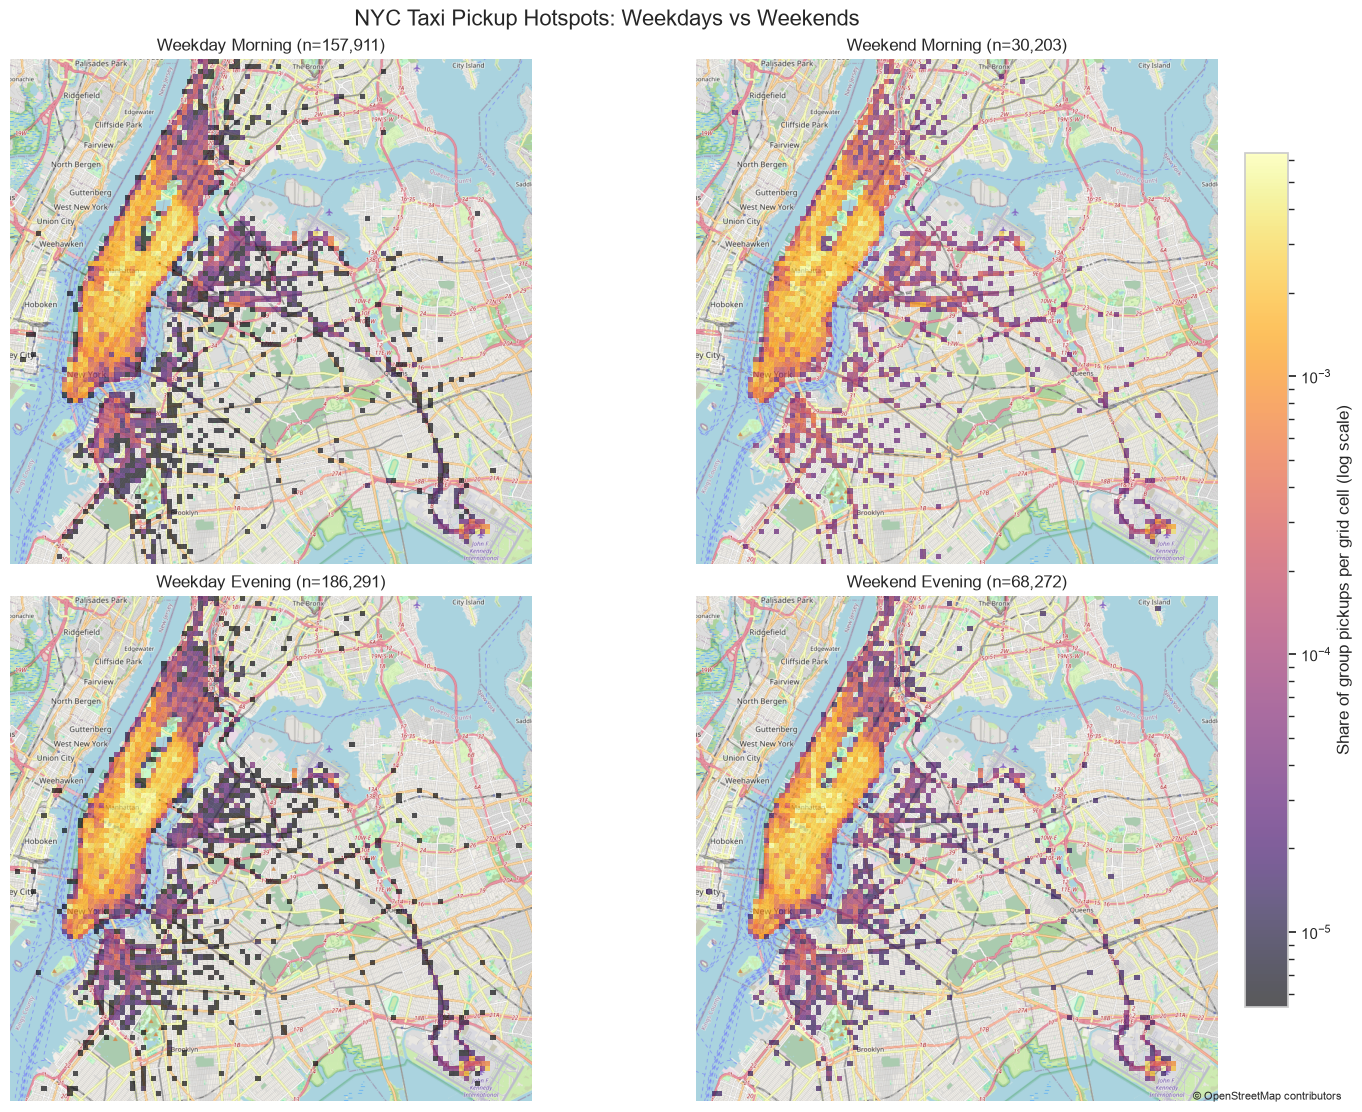

In [40]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from PIL import Image
from io import BytesIO
from math import floor, radians, tan, log, pi
from matplotlib.colors import LogNorm


# --------------------------------------------------
# 1. Prepare the data
# --------------------------------------------------

df_map = df_clean.copy()

df_map["pickup_datetime"] = pd.to_datetime(
    df_map["pickup_datetime"], errors="coerce"
)

df_map = df_map.dropna(subset=[
    "pickup_datetime",
    "pickup_longitude",
    "pickup_latitude"
])

# Keep the geographic bounds used in our analysis
lon_min, lon_max = -74.05, -73.75
lat_min, lat_max = 40.63, 40.85

df_map = df_map[
    df_map["pickup_longitude"].between(lon_min, lon_max)
    & df_map["pickup_latitude"].between(lat_min, lat_max)
].copy()

# Classify trips using the pickup date
df_map["day_type"] = np.where(
    df_map["pickup_datetime"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

hour = df_map["pickup_datetime"].dt.hour

df_map["time_period"] = np.select(
    [
        hour.between(7, 9),
        hour.between(17, 19)
    ],
    ["Morning", "Evening"],
    default="Other"
)

groups = [
    ("Weekday", "Morning"),
    ("Weekend", "Morning"),
    ("Weekday", "Evening"),
    ("Weekend", "Evening")
]

df_map = df_map[
    df_map["time_period"].isin(["Morning", "Evening"])
].copy()


# --------------------------------------------------
# 2. Download a static NYC street map
#    No contextily or rasterio required
# --------------------------------------------------

zoom = 12
tile_count = 2 ** zoom
earth_radius = 6378137
world_half = pi * earth_radius


def lon_to_tile(lon):
    return (lon + 180) / 360 * tile_count


def lat_to_tile(lat):
    lat_rad = radians(lat)
    return (
        1 - np.arcsinh(np.tan(lat_rad)) / pi
    ) / 2 * tile_count


# Find which map tiles cover our NYC bounds
x_start = floor(lon_to_tile(lon_min))
x_end = floor(lon_to_tile(lon_max))
y_start = floor(lat_to_tile(lat_max))
y_end = floor(lat_to_tile(lat_min))

# Combine the tiles into one background image
tile_size = 256

map_image = Image.new(
    "RGB",
    (
        (x_end - x_start + 1) * tile_size,
        (y_end - y_start + 1) * tile_size
    )
)

for x in range(x_start, x_end + 1):
    for y in range(y_start, y_end + 1):

        url = f"https://tile.openstreetmap.org/{zoom}/{x}/{y}.png"

        response = requests.get(
            url,
            headers={"User-Agent": "NYC-Taxi-Analysis/1.0"},
            timeout=20
        )
        response.raise_for_status()

        tile = Image.open(BytesIO(response.content)).convert("RGB")

        map_image.paste(
            tile,
            (
                (x - x_start) * tile_size,
                (y - y_start) * tile_size
            )
        )

# Calculate the geographic extent of the background image
tile_width = 2 * world_half / tile_count

map_left = -world_half + x_start * tile_width
map_right = -world_half + (x_end + 1) * tile_width
map_top = world_half - y_start * tile_width
map_bottom = world_half - (y_end + 1) * tile_width

map_extent = [
    map_left, map_right, map_bottom, map_top
]


# --------------------------------------------------
# 3. Convert pickup coordinates to map coordinates
# --------------------------------------------------

def to_web_mercator(lon, lat):
    x = earth_radius * np.radians(lon)
    y = earth_radius * np.log(
        np.tan(np.pi / 4 + np.radians(lat) / 2)
    )
    return x, y


df_map["x"], df_map["y"] = to_web_mercator(
    df_map["pickup_longitude"].to_numpy(),
    df_map["pickup_latitude"].to_numpy()
)

x_min, y_min = to_web_mercator(lon_min, lat_min)
x_max, y_max = to_web_mercator(lon_max, lat_max)


# --------------------------------------------------
# 4. Calculate the same grid for all four groups
# --------------------------------------------------

number_of_bins = 100

x_edges = np.linspace(x_min, x_max, number_of_bins + 1)
y_edges = np.linspace(y_min, y_max, number_of_bins + 1)

heatmaps = {}
positive_values = []

for day, period in groups:

    subset = df_map[
        (df_map["day_type"] == day)
        & (df_map["time_period"] == period)
    ]

    if subset.empty:
        raise ValueError(f"No trips found for {day} {period}.")

    # Count pickups in each grid cell
    counts, _, _ = np.histogram2d(
        subset["x"],
        subset["y"],
        bins=[x_edges, y_edges]
    )

    # Normalise so groups with different trip totals
    # can be compared by spatial distribution
    density = counts / len(subset)

    heatmaps[(day, period)] = (density, len(subset))

    positive_values.extend(
        density[density > 0].tolist()
    )

# One shared logarithmic scale for all four panels
vmin = np.percentile(positive_values, 5)
vmax = np.percentile(positive_values, 99.5)

if vmax <= vmin:
    vmax = vmin * 1.01

colour_scale = LogNorm(vmin=vmin, vmax=vmax)


# --------------------------------------------------
# 5. Draw the static heatmaps
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11),
    constrained_layout=True
)

for ax, (day, period) in zip(axes.flat, groups):

    density, trip_count = heatmaps[(day, period)]

    # Draw the labelled street map first
    ax.imshow(
        map_image,
        extent=map_extent,
        origin="upper",
        zorder=0
    )

    # Overlay the pickup-density grid
    density = np.ma.masked_less_equal(density.T, 0)

    heatmap = ax.pcolormesh(
        x_edges,
        y_edges,
        density,
        cmap="inferno",
        norm=colour_scale,
        alpha=0.65,
        shading="auto",
        zorder=1
    )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal")
    ax.set_title(f"{day} {period} (n={trip_count:,})")
    ax.set_axis_off()

# One colour bar for the whole figure
fig.colorbar(
    heatmap,
    ax=axes.ravel().tolist(),
    label="Share of group pickups per grid cell (log scale)",
    shrink=0.82,
    pad=0.02
)

fig.suptitle(
    "NYC Taxi Pickup Hotspots: Weekdays vs Weekends",
    fontsize=16
)

# Required attribution for the street-map tiles
fig.text(
    0.99, 0.005,
    "© OpenStreetMap contributors",
    ha="right",
    fontsize=8
)

# Save a high-resolution static figure
plt.savefig(
    "nyc_static_pickup_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Findings and interpretation

The heatmaps show the geographic distribution of taxi pickups during weekday and weekend mornings (07:00–09:59) and evenings (17:00–19:59). The same geographic grid and colour scale are used across all four panels to make spatial comparisons easier.

The brightest areas indicate locations with the highest relative concentration of pickups within each group. Comparing weekdays with weekends can reveal whether pickup activity is concentrated in different areas or distributed differently across the city. Comparing morning and evening periods can also reveal changes in the locations where pickups are concentrated.

These patterns should be interpreted in terms of the relative share of pickups because the heatmaps are normalised by the total number of pickups in each group.

# 4.2 Hotspots

If you were a taxi driver wanting to plan your evenings so that you could get the most trips, you would want to know where the popular areas are. 
Looking at the time periods 23:00 on a Friday evening to 02:00 on a Saturday morning, and between 17:00 and 20:00 on a Thursday, find hotspot locations (areas where there are a large number of trips happening).
If you were to use k-means, you would define the number of clusters. However, here the number of clusters is not at all clear. DBSCAN (available in sklearn) determines this for you, and works well on spatial data.
DBSCAN has two configurable parameters: ϵ the maximum distance between any two points, and the minimum number of samples to determine a cluster. 
Your hotspot location might be defined as at least 15 pickups in that location in an hour, and locations might be required to be within 50 or 100 metres from each other (motivate your choice of parameters). Using DBSCAN, identify clusters and plot these on a map. How many clusters
did you find? [8 marks]


In [41]:
# Load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# 1. Load the data
df = pd.read_csv(
    "../data/train.csv",
    parse_dates=["pickup_datetime"]
)

# 2. Keep rows with valid pickup information
df = df.dropna(subset=[
    "pickup_datetime",
    "pickup_longitude",
    "pickup_latitude"
]).copy()

# 3. Keep pickups within our NYC map area
df = df[
    df["pickup_longitude"].between(-74.05, -73.75)
    & df["pickup_latitude"].between(40.63, 40.85)
].copy()

# 4. Extract day and hour
df["day"] = df["pickup_datetime"].dt.dayofweek
df["hour"] = df["pickup_datetime"].dt.hour

# 5. Select the two requested periods
friday_night = (
    (df["day"] == 4) & (df["hour"] == 23)
) | (
    (df["day"] == 5) & (df["hour"].between(0, 1))
)

thursday_evening = (
    (df["day"] == 3) & (df["hour"].between(17, 19))
)

df["period"] = np.select(
    [friday_night, thursday_evening],
    ["Friday night", "Thursday evening"],
    default="Other"
)

df = df[df["period"] != "Other"].copy()

print("Selected pickups:")
print(df["period"].value_counts())
print("Total selected pickups:", len(df))


Selected pickups:
period
Thursday evening    38255
Friday night        34868
Name: count, dtype: int64
Total selected pickups: 73123


In [42]:
# Find the clusters

# DBSCAN settings
earth_radius_km = 6371.0088
epsilon = 0.15 / earth_radius_km  # 150 metres in radians
min_pickups = 15

# Store the results
results = []

# Analyse each period, one hour at a time
for period in ["Friday night", "Thursday evening"]:

    period_data = df[df["period"] == period]

    for hour_start, group in period_data.groupby(
        period_data["pickup_datetime"].dt.floor("h")
    ):

        # DBSCAN requires [latitude, longitude] in radians
        coords = np.radians(
            group[["pickup_latitude", "pickup_longitude"]].to_numpy()
        )

        # Find clusters
        db = DBSCAN(
            eps=epsilon,
            min_samples=min_pickups,
            metric="haversine",
            algorithm="ball_tree"
        )

        labels = db.fit_predict(coords)

        # Count the clusters, ignoring noise labelled -1
        group = group.copy()
        group["cluster"] = labels

        for cluster_id, cluster in group[
            group["cluster"] != -1
        ].groupby("cluster"):

            results.append({
                "period": period,
                "hour": hour_start,
                "cluster": cluster_id,
                "latitude": cluster["pickup_latitude"].mean(),
                "longitude": cluster["pickup_longitude"].mean(),
                "pickups": len(cluster)
            })


# Put all detected clusters into a DataFrame
columns = [
    "period", "hour", "cluster",
    "latitude", "longitude", "pickups"
]

clusters = pd.DataFrame(results, columns=columns)

if clusters.empty:
    print("No clusters were found.")
    print("Try increasing epsilon from 100 metres to 150 metres.")
else:
    print("Clusters found:")
    print(clusters.groupby("period").size())

    print("\nTotal hourly cluster detections:", len(clusters))

    print("\nLargest clusters:")
    print(
        clusters.sort_values("pickups", ascending=False)
        .head(10)
        .to_string(index=False)
    )


Clusters found:
period
Friday night        4
Thursday evening    2
dtype: int64

Total hourly cluster detections: 6

Largest clusters:
          period                hour  cluster  latitude  longitude  pickups
Thursday evening 2016-01-28 19:00:00        0    40.770    -73.863       17
    Friday night 2016-01-30 01:00:00        0    40.719    -73.990       16
    Friday night 2016-03-26 01:00:00        0    40.723    -73.987       16
    Friday night 2016-04-16 01:00:00        0    40.740    -74.006       16
    Friday night 2016-06-11 01:00:00        0    40.741    -74.006       15
Thursday evening 2016-01-07 18:00:00        0    40.749    -73.992       15


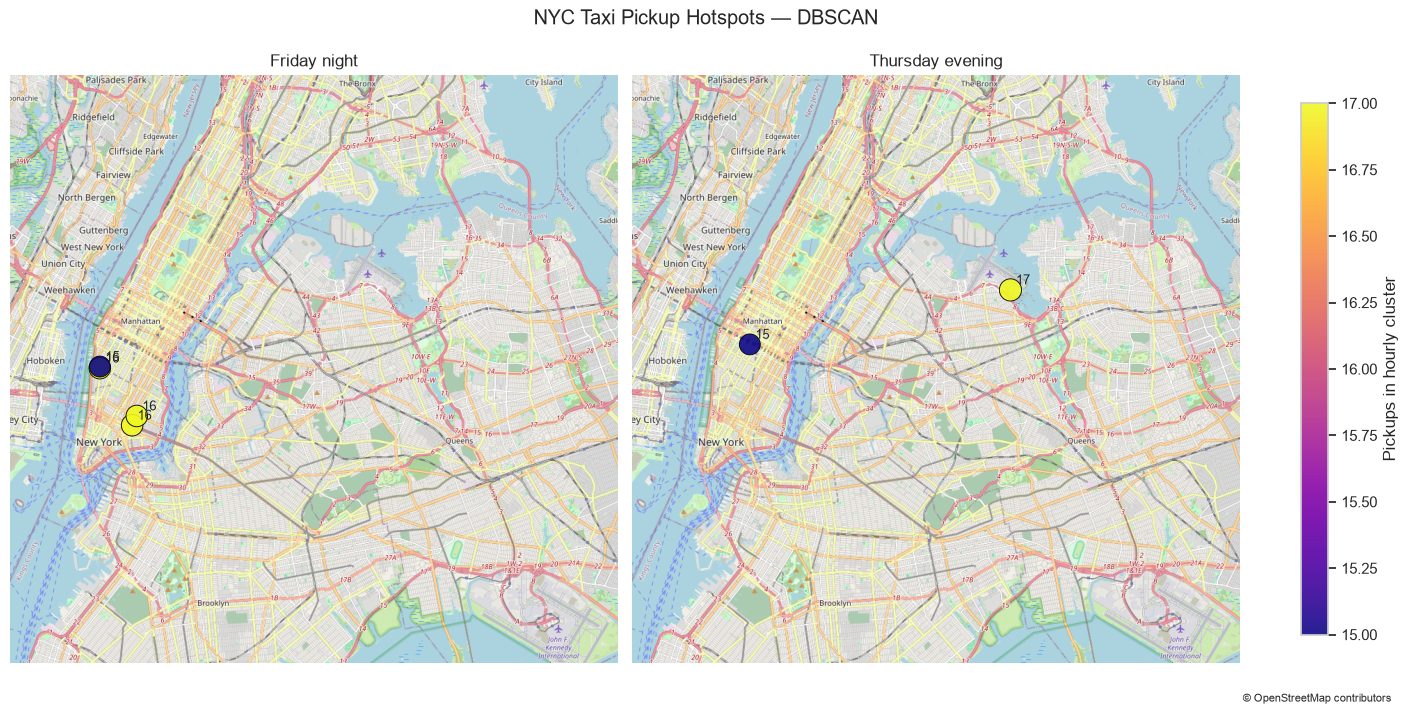

In [ ]:

import requests
from PIL import Image
from io import BytesIO
from math import floor, pi

# 1. Map area around NYC
lon_min, lon_max = -74.05, -73.75
lat_min, lat_max = 40.63, 40.85

zoom = 12
tile_count = 2 ** zoom
tile_size = 256
earth_radius = 6378137
world_half = pi * earth_radius

# 2. Convert longitude and latitude to map tile numbers
def lon_to_tile(lon):
    return (lon + 180) / 360 * tile_count

def lat_to_tile(lat):
    return (
        1 - np.arcsinh(np.tan(np.radians(lat))) / pi
    ) / 2 * tile_count

x_start = floor(lon_to_tile(lon_min))
x_end = floor(lon_to_tile(lon_max))
y_start = floor(lat_to_tile(lat_max))
y_end = floor(lat_to_tile(lat_min))

# 3. Download only the tiles needed for this map
map_image = Image.new(
    "RGB",
    (
        (x_end - x_start + 1) * tile_size,
        (y_end - y_start + 1) * tile_size
    )
)

for x in range(x_start, x_end + 1):
    for y in range(y_start, y_end + 1):
        url = f"https://tile.openstreetmap.org/{zoom}/{x}/{y}.png"

        response = requests.get(
            url,
            headers={"User-Agent": "NYCTaxiCoursework/1.0"},
            timeout=20
        )
        response.raise_for_status()

        tile = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        map_image.paste(
            tile,
            (
                (x - x_start) * tile_size,
                (y - y_start) * tile_size
            )
        )

# 4. Calculate the geographic extent of the downloaded map
tile_width = 2 * world_half / tile_count

map_extent = [
    -world_half + x_start * tile_width,
    -world_half + (x_end + 1) * tile_width,
    world_half - (y_end + 1) * tile_width,
    world_half - y_start * tile_width
]

# 5. Convert hotspot coordinates to the same map projection
def to_web_mercator(lon, lat):
    x = earth_radius * np.radians(lon)
    y = earth_radius * np.log(
        np.tan(np.pi / 4 + np.radians(lat) / 2)
    )
    return x, y

x_min, y_min = to_web_mercator(lon_min, lat_min)
x_max, y_max = to_web_mercator(lon_max, lat_max)

# 6. Plot the two time periods on street maps
fig, axes = plt.subplots(
    1, 2, figsize=(14, 7),
    constrained_layout=True
)

for ax, period in zip(
    axes, ["Friday night", "Thursday evening"]
):
    # Street map background
    ax.imshow(
        map_image,
        extent=map_extent,
        origin="upper"
    )

    data = clusters[clusters["period"] == period].copy()

    if not data.empty:
        data["x"], data["y"] = to_web_mercator(
            data["longitude"].to_numpy(),
            data["latitude"].to_numpy()
        )

        points = ax.scatter(
            data["x"],
            data["y"],
            s=data["pickups"] * 15,
            c=data["pickups"],
            cmap="plasma",
            edgecolor="black",
            linewidth=0.7,
            alpha=0.9
        )

        for _, row in data.iterrows():
            ax.annotate(
                str(row["pickups"]),
                (row["x"], row["y"]),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=9
            )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(period)
    ax.set_axis_off()

if not clusters.empty:
    fig.colorbar(
        points,
        ax=axes,
        label="Pickups in hourly cluster",
        shrink=0.8
    )

fig.suptitle("NYC Taxi Pickup Hotspots — DBSCAN")
fig.text(
    0.99, 0.005,
    "© OpenStreetMap contributors",
    ha="right", fontsize=8
)

plt.savefig(
    "nyc_dbscan_street_map.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
